# Historical photographs — first look at `Data_mappe.csv`

This table is the swisstopo historical-photograph catalogue behind the map in this repository. Each row is one exposure: an inventory number, a title, a description, a date, and, for a subset reviewed with the Ortsfinder prototype, a place.

The CSV is an export. A title row (`Table 1`) sits above the header, empty cells are often the literal token `<Null>`, and the same date is written in several formats. This notebook cleans that enough to see what the catalogue contains: how complete each field is, which years the photographs cover, and how far the geolocation has got.

`convertir_donnees.py` builds `data_photos.js` from the Excel sibling of this file. That file stores dates such as `Apr-21` as real dates, so the script gets their year without the parsing done below. Place names and coordinates come from the Ortsfinder prototype; the export itself says those results still need checking.

In [1]:
%matplotlib inline

from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 120)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
    "font.size": 11,
})

candidates = [Path("data/Data_mappe.csv"), Path("../data/Data_mappe.csv")]
csv_path = next(path for path in candidates if path.exists())

# The first line of the file is the export title "Table 1", so the header is the second line.
# keep_default_na would also swallow the text "N/A", which here means "year unknown".
raw = pd.read_csv(csv_path, skiprows=1, keep_default_na=False, na_values=[""])
raw = raw.replace({"<Null>": pd.NA})
raw["Jahr"] = raw["Jahr"].replace({"N/A": pd.NA})

# The unnamed spacer and the attribution column are empty. Place columns stay,
# including Verbundener_Ort_GND_ID, which is empty but belongs to the place schema.
empty_columns = [
    column for column in raw.columns
    if raw[column].isna().all() and (str(column).startswith("Unnamed") or str(column).startswith("©"))
]
raw = raw.drop(columns=empty_columns)

raw["_filled"] = raw.notna().sum(axis=1)
duplicate_ids = raw.loc[raw["NAME"].duplicated(keep=False), "NAME"].unique()
photos = (
    raw.sort_values("_filled", ascending=False)
    .drop_duplicates("NAME")
    .sort_values("Inv")
    .drop(columns="_filled")
    .reset_index(drop=True)
)

print(f"Read {csv_path}")
print(f"{len(raw)} rows in the export, {len(photos)} photos after removing {len(duplicate_ids)} duplicated ids")
print(f"Dropped columns with no values: {empty_columns}")
print(f"Inv is unique: {photos['Inv'].is_unique}, nummer is unique: {photos['nummer'].is_unique}")

Matplotlib is building the font cache; this may take a moment.


Read ../data/Data_mappe.csv
1778 rows in the export, 1771 photos after removing 7 duplicated ids
Dropped columns with no values: ['Unnamed: 3', '© Data: swisstopo – Ortsfinder-Prototyp, Ergebnisse prüfen']
Inv is unique: True, nummer is unique: True


## What the columns hold

Seven photo ids occur twice in the export. In each pair, one row carries the place fields and the other leaves them blank. The fuller row is the one kept, which is the same choice `convertir_donnees.py` makes.

Two columns were empty on every row and are dropped: an unnamed spacer, and a trailing column whose header is the Ortsfinder attribution (`© Data: swisstopo – Ortsfinder-Prototyp, Ergebnisse prüfen`). That attribution applies to the place columns below.

In [2]:
glossary = pd.DataFrame(
    [
        ("NAME", "Identifier of the photograph"),
        ("Spalte1", "Identifier of the group. Up to four exposures share one"),
        ("Inv", "Inventory number. The map builds the Memobase id from it"),
        ("nummer", "Negative or dossier number, sometimes with a letter suffix"),
        ("Name2", "Title"),
        ("Beschreibung", "What the picture shows"),
        ("TnA Collection", "Collection code. Filled on the edited extract only; the code list is not in this file"),
        ("TnA Categoriy", "Category code, on the same extract. The heading is spelled this way in the file"),
        ("min date", "Start of the recorded date"),
        ("max date", "End of the recorded date"),
        ("Jahr", "Year or date as text. The export writes an unknown year as N/A"),
        ("Tags", "Photographer, written as 'Author: …'"),
        ("Bemerkungen ", "Free remark. The column name has a trailing space in the file"),
        ("COLUMN", "Row number from the edited extract; blank everywhere else"),
        ("Spalte14", "Editor login, on the edited extract"),
        ("Spalte15", "Timestamp of that edit"),
        ("Spalte16", "Second editor login"),
        ("Spalte17", "Timestamp of the second edit"),
        ("Abgebildeter_Ort_Name", "Name of the place depicted"),
        ("Abgebildeter_Ort_E_LV95", "Easting of that place, LV95"),
        ("Abgebildeter_Ort_N_LV95", "Northing of that place, LV95"),
        ("Abgebildeter_Ort_Quelle", "Source of that place (swisstopo, GND, manual)"),
        ("Abgebildeter_Ort_GND_ID", "GND identifier of that place"),
        ("Aufnahmeort_Name", "Name of the camera position"),
        ("Aufnahmeort_E_LV95", "Easting of the camera position, LV95"),
        ("Aufnahmeort_N_LV95", "Northing of the camera position, LV95"),
        ("Aufnahmeort_Quelle", "Source of the camera position"),
        ("Aufnahmeort_GND_ID", "GND identifier of the camera position"),
        ("Verbundener_Ort_Name", "Name of a related place"),
        ("Verbundener_Ort_E_LV95", "Easting of the related place, LV95"),
        ("Verbundener_Ort_N_LV95", "Northing of the related place, LV95"),
        ("Verbundener_Ort_Quelle", "Source of the related place"),
        ("Verbundener_Ort_GND_ID", "GND identifier of the related place"),
        ("Ortsfinder_Status", "Review state from the Ortsfinder prototype"),
        ("Ortsfinder_Datum", "Date of that review"),
    ],
    columns=["column", "contents"],
)

filled = (photos.notna().mean() * 100).rename("filled_pct")
overview = glossary.merge(filled, left_on="column", right_index=True, how="left")
overview["filled"] = overview["filled_pct"].map(lambda value: f"{value:.1f}%")
overview = overview.drop(columns="filled_pct")
overview

,column,contents,filled
0,NAME,Identifier of the photograph,100.0%
1,Spalte1,Identifier of the group. Up to four exposures share one,100.0%
2,Inv,Inventory number. The map builds the Memobase id from it,100.0%
3,nummer,"Negative or dossier number, sometimes with a letter suffix",100.0%
4,Name2,Title,100.0%
5,Beschreibung,What the picture shows,100.0%
6,TnA Collection,Collection code. Filled on the edited extract only; the code list is not in this file,4.0%
7,TnA Categoriy,"Category code, on the same extract. The heading is spelled this way in the file",4.0%
8,min date,Start of the recorded date,100.0%
9,max date,End of the recorded date,100.0%


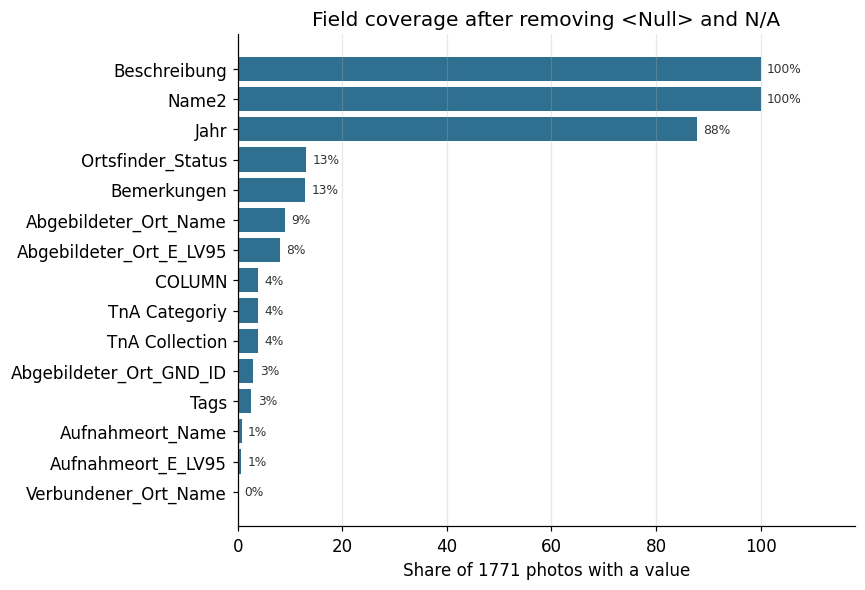

In [3]:
# Identity fields are complete on every photo, so the chart keeps the fields whose coverage varies.
chart_columns = [
    "Name2", "Beschreibung", "Jahr", "Tags", "Bemerkungen ",
    "TnA Collection", "TnA Categoriy", "COLUMN",
    "Abgebildeter_Ort_Name", "Abgebildeter_Ort_E_LV95", "Abgebildeter_Ort_GND_ID",
    "Aufnahmeort_Name", "Aufnahmeort_E_LV95",
    "Verbundener_Ort_Name",
    "Ortsfinder_Status",
]
rates = (photos[chart_columns].notna().mean() * 100).sort_values(ascending=True)
labels = [column.rstrip() for column in rates.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(labels, rates.values, color="#2f6f8f")
for position, value in enumerate(rates.values):
    ax.text(value + 1.2, position, f"{value:.0f}%", va="center", fontsize=8, color="#333")
ax.set_xlim(0, 118)
ax.set_xlabel(f"Share of {len(photos)} photos with a value")
ax.set_title("Field coverage after removing <Null> and N/A")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Dates

`Jahr` is a plain year for most photographs (`1919`), and a date for the rest: `June 1914`, `Apr-21`, `6/16/01`, `1/20/28`, plus a handful of ranges (`1935-1936`) and one `before 1906`. `min date` and `max date` repeat that information in two notations. Dotted values are day.month.year (`20.01.28`). Slashed values are month/day/year (`1/20/28`), which is how the spreadsheet rewrote some of them.

Two placeholders mark an unknown date: `Jahr` equal to `N/A`, and `min date` of `01.01.1000`. A two-digit year is read as 1900–1999. That fits the dated photographs in this export, from the triangulation campaigns of the 1900s through the 1989 Federal Council visit and the 1992 staff magazine. Years that are already written with four digits are kept as written, which is what preserves 1852, 1898 and the single year 2000.

A search for four digits in this text would miss `Apr-21` and `6/16/01`. The map is not affected: `convertir_donnees.py` reads the Excel file, where those cells are real dates, and `data_photos.js` has a year for them.

In [4]:
MONTHS = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12,
}


def expand_year(year, hint=None):
    """Turn a year as written into a full year.

    Four-digit years before 1800 are the empty-date marker (year 1000).
    A two-digit year lands in 1900–1999, unless `hint` is a four-digit year
    with the same last two digits, so that 98 next to 1898 stays 1898
    and 00 next to 2000 stays 2000.
    """
    if year >= 1000:
        return None if year < 1800 else year
    if hint is not None and hint % 100 == year:
        return hint
    return 1900 + year


def parse_date(value, hint=None):
    """Parse one date cell. Dotted form is day.month.year; slashed form is month/day/year."""
    if value is None or (isinstance(value, float) and pd.isna(value)) or pd.isna(value):
        return None
    text = str(value).strip()
    if text == "":
        return None
    dotted = re.match(r"^(\d{1,2})\.(\d{1,2})\.(\d{2,4})", text)
    slashed = re.match(r"^(\d{1,2})/(\d{1,2})/(\d{2,4})$", text)
    if dotted:
        day, month, year = (int(dotted.group(i)) for i in (1, 2, 3))
    elif slashed:
        month, day, year = (int(slashed.group(i)) for i in (1, 2, 3))
    else:
        return None
    year = expand_year(year, hint)
    if year is None or not (1 <= month <= 12 and 1 <= day <= 31):
        return None
    try:
        return pd.Timestamp(year=year, month=month, day=day)
    except ValueError:
        return None


def parse_jahr(value):
    """Read the free-text Jahr cell.

    Returns year_from, year_to and a kind:
    missing, year, month, day, range, before, or unparsed.
    """
    if value is None or pd.isna(value):
        return pd.NA, pd.NA, "missing"
    text = re.sub(r"\s+", " ", str(value).strip())
    if text in ("", "N/A"):
        return pd.NA, pd.NA, "missing"

    match = re.fullmatch(r"before\s+(\d{4})", text, flags=re.I)
    if match:
        return pd.NA, int(match.group(1)), "before"

    match = re.fullmatch(r"(\d{4})\s*-\s*(\d{4})", text)
    if match:
        return int(match.group(1)), int(match.group(2)), "range"

    match = re.fullmatch(r"(\d{4})", text)
    if match:
        return int(match.group(1)), int(match.group(1)), "year"

    match = re.fullmatch(r"([A-Za-z]+)-(\d{2,4})", text)
    if match and match.group(1).lower()[:3] in MONTHS:
        year = expand_year(int(match.group(2)))
        return year, year, "month"

    match = re.fullmatch(r"([A-Za-z]+)\s+(\d{4})", text)
    if match and match.group(1).lower()[:3] in MONTHS:
        year = int(match.group(2))
        return year, year, "month"

    if re.fullmatch(r"\d{1,2}/\d{1,2}/\d{2,4}", text):
        stamp = parse_date(text)
        if stamp is not None:
            return int(stamp.year), int(stamp.year), "day"

    return pd.NA, pd.NA, "unparsed"


def refine_precision(kind, year_from, year_to, date_min, date_max):
    """Use min/max to tell a full year from a month or a single day."""
    if kind != "year" or pd.isna(year_from) or date_min is None or date_max is None:
        return kind
    if date_min.year != year_from or date_max.year != year_to:
        return kind
    if date_min == date_max:
        return "day"
    same_month = date_min.month == date_max.month
    if same_month and date_min.day == 1 and date_max.day == date_max.days_in_month:
        return "month"
    full_year = (
        date_min == pd.Timestamp(year=int(year_from), month=1, day=1)
        and date_max == pd.Timestamp(year=int(year_from), month=12, day=31)
    )
    if full_year:
        return "year"
    return "within year"


def year_as_on_the_map(value):
    """First four-digit year in the text: the rule annee() in convertir_donnees.py applies to text cells.

    That script reads the Excel file, where Apr-21 and 6/16/01 are real dates and keep their year.
    Here the rule runs on the CSV text, to show which years a plain four-digit search would miss.
    """
    if value is None or pd.isna(value):
        return pd.NA
    match = re.search(r"(1[89]\d\d|20\d\d)", str(value))
    return int(match.group(1)) if match else pd.NA


# A few rows the parser has to get right. These are real shapes from the export.
assert parse_jahr("1919") == (1919, 1919, "year")
assert parse_jahr("Apr-21") == (1921, 1921, "month")
assert parse_jahr("June 1914") == (1914, 1914, "month")
assert parse_jahr("1/20/28") == (1928, 1928, "day")
assert parse_jahr("1935-1936") == (1935, 1936, "range")
y0, y1, kind = parse_jahr("before 1906")
assert kind == "before" and pd.isna(y0) and y1 == 1906
assert parse_date("20.01.28 00:00:00.000000000") == pd.Timestamp("1928-01-20")
assert parse_date("06.05.53 00:00:00.000000000") == pd.Timestamp("1953-05-06")
assert parse_date("01.01.1000") is None
assert parse_date("01.01.98", hint=1898) == pd.Timestamp("1898-01-01")
assert parse_date("01.01.00 00:00:00.000000000", hint=2000) == pd.Timestamp("2000-01-01")
assert parse_date("10.07.88 00:00:00.000000000") == pd.Timestamp("1988-07-10")
assert parse_date("6/16/01") == pd.Timestamp("1901-06-16")
assert parse_date("12/31/06", hint=1906) == pd.Timestamp("1906-12-31")
print("Date parser checks passed")

Date parser checks passed


In [5]:
parsed_jahr = photos["Jahr"].apply(parse_jahr)
photos["year_from"] = parsed_jahr.map(lambda item: item[0]).astype("Int64")
photos["year_to"] = parsed_jahr.map(lambda item: item[1]).astype("Int64")
photos["jahr_kind"] = parsed_jahr.map(lambda item: item[2])

hints = photos["year_to"].fillna(photos["year_from"])
photos["date_min"] = [
    parse_date(value, None if pd.isna(hint) else int(hint))
    for value, hint in zip(photos["min date"], hints)
]
photos["date_max"] = [
    parse_date(value, None if pd.isna(hint) else int(hint))
    for value, hint in zip(photos["max date"], hints)
]
photos["date_min"] = pd.to_datetime(pd.Series(photos["date_min"], dtype="object"))
photos["date_max"] = pd.to_datetime(pd.Series(photos["date_max"], dtype="object"))
photos["precision"] = [
    refine_precision(kind, y0, y1, d0, d1)
    for kind, y0, y1, d0, d1 in zip(
        photos["jahr_kind"], photos["year_from"], photos["year_to"], photos["date_min"], photos["date_max"]
    )
]

same_year = photos["year_from"].notna() & (photos["year_from"] == photos["year_to"])
photos["year"] = photos["year_from"].where(same_year).astype("Int64")
photos["map_year"] = photos["Jahr"].map(year_as_on_the_map).astype("Int64")

unparsed = photos.loc[photos["jahr_kind"] == "unparsed", "Jahr"]
print(f"Jahr values the parser could not read: {len(unparsed)}")
if len(unparsed):
    display(unparsed.value_counts())

year_clash = photos[
    photos["date_min"].notna()
    & photos["year_from"].notna()
    & (photos["date_min"].dt.year != photos["year_from"])
]
print(f"Rows where min date and Jahr disagree on the year: {len(year_clash)}")
if len(year_clash):
    display(year_clash[["Inv", "Name2", "Jahr", "min date", "year_from", "date_min"]])

precision_labels = {
    "missing": "No year",
    "year": "Whole year",
    "month": "A single month",
    "day": "A single day",
    "within year": "Several days inside one year",
    "range": "Spans more than one year",
    "before": "Upper bound only (before 1906)",
}
precision_counts = (
    photos["precision"].value_counts()
    .rename(index=precision_labels)
    .rename("photos")
    .to_frame()
)
precision_counts["share"] = (precision_counts["photos"] / len(photos) * 100).map(lambda value: f"{value:.1f}%")
precision_counts

Jahr values the parser could not read: 0
Rows where min date and Jahr disagree on the year: 0


,photos,share
precision,,
Whole year,1379,77.9%
No year,217,12.3%
A single day,98,5.5%
A single month,74,4.2%
Spans more than one year,2,0.1%
Upper bound only (before 1906),1,0.1%


1551 photographs have a single year, 220 do not. The fullest year is 1919 (338 photographs). 82% of the dated photographs fall in 1910–1929.
How the 1919 photographs are dated:


,photos
precision,
year,330
day,8


135 photographs have a year here only because Apr-21 and 6/16/01 are read as dates; a four-digit search on this CSV text would miss them. The map already has these years: its script reads the Excel file, where they are real dates.


,Inv,Name2,Jahr,year
9,389699,Wisenberg,6/16/01,1901
32,389723,Lötschberg,9/30/06,1906
54,389745,Poncione della Freccione [Puntone dei Fraciòn],6/4/14,1914
82,389776,Finsteraarhorn,Sep-14,1914
108,389859,Monte Rosa,Sep-14,1914
111,389863,Bütschelegg,6/20/14,1914
114,389868,Chasseral,5/22/14,1914
115,389869,Chasseral,5/22/14,1914


3 photographs have a four-digit year the map would keep, and no single year here:


,Inv,Name2,Jahr,map_year,date_min,date_max
535,390707,Becker Fridolin,before 1906,1906,NaT,1906-12-31
698,391105,Lienheim,1935-1936,1935,1935-01-01,1936-12-31
1293,392640,Spiez,1910-1950,1910,1910-01-01,1950-12-31


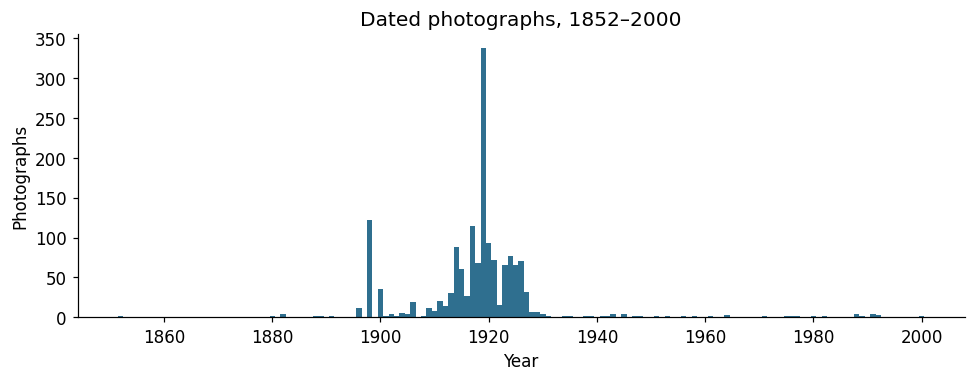

In [6]:
dated = photos.loc[photos["year"].notna(), "year"].astype(int)
counts = dated.value_counts().sort_index()
peak_year = int(counts.idxmax())
early = dated.between(1910, 1929).mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(counts.index, counts.values, width=1, color="#2f6f8f")
ax.set_xlabel("Year")
ax.set_ylabel("Photographs")
ax.set_title(f"Dated photographs, {dated.min()}–{dated.max()}")
fig.tight_layout()

print(
    f"{len(dated)} photographs have a single year, "
    f"{int(photos['year'].isna().sum())} do not. "
    f"The fullest year is {peak_year} ({int(counts.max())} photographs). "
    f"{early:.0%} of the dated photographs fall in 1910–1929."
)
print(f"How the {peak_year} photographs are dated:")
display(photos.loc[photos["year"] == peak_year, "precision"].value_counts().rename("photos").to_frame())

outside_map = photos[photos["year"].notna() & photos["map_year"].isna()]
withheld = photos[photos["year"].isna() & photos["map_year"].notna()]
print(
    f"{len(outside_map)} photographs have a year here only because Apr-21 and 6/16/01 are read as dates; "
    f"a four-digit search on this CSV text would miss them. "
    f"The map already has these years: its script reads the Excel file, where they are real dates."
)
display(outside_map[["Inv", "Name2", "Jahr", "year"]].head(8))
print(f"{len(withheld)} photographs have a four-digit year the map would keep, and no single year here:")
display(withheld[["Inv", "Name2", "Jahr", "map_year", "date_min", "date_max"]])

## Titles, remarks, authors

Every photograph has a title and a description. Both repeat, because one subject was often exposed several times and several photographs share a group id (`Spalte1`). `Tags` is the photographer line. `Bemerkungen` is a free note, used for things like the physical negative, a staff portrait, or a cross-reference. The descriptions have their own section below.

In [7]:
print(f"{photos['Name2'].nunique()} distinct titles, {photos['Beschreibung'].nunique()} distinct descriptions")
print(f"{photos['Tags'].notna().sum()} photographs name a photographer, {photos['Bemerkungen '].notna().sum()} carry a remark")

group_size = photos.groupby("Spalte1")["Inv"].transform("size")
size_counts = group_size.value_counts().sort_index().rename("photographs").to_frame()
size_counts.index.name = "photographs sharing a group id"
print("Group size")
display(size_counts)

print("Most frequent titles")
display(photos["Name2"].value_counts().head(12).rename("photos").to_frame())

1189 distinct titles, 795 distinct descriptions
46 photographs name a photographer, 228 carry a remark
Group size


,photographs
photographs sharing a group id,
1,1243
2,414
3,78
4,36


Most frequent titles


,photos
Name2,
"Motto d'Arbino [Arbedo-Castione, Motto d'Arbino]",20
Rosablanche,17
Neuchâtel,13
Finsteraarhorn,12
Lac de Montsalvens,12
Puntone dei Fraciòn,11
"Bagnes, Rosablanche",9
La Chaux-de-Fonds,9
Monte Rosa,8


In [8]:
authors = (
    photos["Tags"]
    .dropna()
    .str.replace(r"^Author:\s*", "", regex=True)
    .value_counts()
    .rename("photos")
    .to_frame()
)
authors.index.name = "photographer"
print(f"{len(authors)} photographer lines")
authors

31 photographer lines


,photos
photographer,
unbekannt,12
"H. Speiser, Basel",2
"G. Metz, Basel",2
E. Wegmann Grundbuchgeometer Mühledorf (Solothurn),2
"Phototypie Co., Neuchâtel",2
"Postkartenverlag Deyhle, Bern",1
"[...]ot., Langenthal",1
"[Verl]ag E. Synnberg & R. v. Pfyffer, Phot., Luzern",1
Photoglob-Wehrli & Vouga & Co. AG. Zürich,1


## Descriptions

The title (`Name2`) is typically a place, and `Beschreibung` names the object photographed there, as in `Piotta` / `Kirchturm` or `Villigen` / `Postgebäude`. Every photograph has one. This section looks at how the descriptions are written, what they name, and what else has been stored in the field.

795 distinct descriptions for 1771 photographs. 628 of them are used once.
The 10 most frequent cover 38% of the photographs, the 50 most frequent 51%.
45% of the descriptions are a single word; the median is 2 words. 56 run to ten words or more.
The longest descriptions:


,Inv,Name2,Beschreibung
1388,392735,Theodolit L+T,"Theodolit System Hildebrand der L+T, Kreis 21 cm, auf Pfeiler im Hof der Landestopografie Bern ; [Instrumentenbeschreibung: Selber oder gleicher Theodolit in der Instrumentensammlung swisstopo. Verwendungszweck: Triangulation. Signatur Nr. 1026; 1027; 1043. (Quelle: Instrumentensammlung swisstopo)]"
121,389879,Puntone dei Fraciòn,Freccionegipfel nach Schneefall am Morgen des 12. Juni 1914. Schneebrucharbeiten vom 3. und 4. Juni zugedeckt. Der Pickel bezeichnet die Stelle des Steinmanns
1212,392466,Rosablanche,"Biwak an der Nordflanke der Alp Severeu, Sicht gegen Petit Combin und Combin de Corbassière, Aufnahmen der Gipfel-Deformation in den Jahren 1891-1921"
1195,392348,Aero-Photogrammetrie,"Kämmerer, Chefingenieur von Th. Scheimpflug (Wien), im Korb des Fesselballons, mit hochgezogenem Aufnahmeapparat Scheimpflug"
541,390718,Hörnlimann Jakob und Etier Paul,"Schiff ""Sondeur"" mit Apparat der L+T, Ingenieur Hörnlimann Jakob und Topograph Etier Paul, Seesondierung auf dem Genfersee"


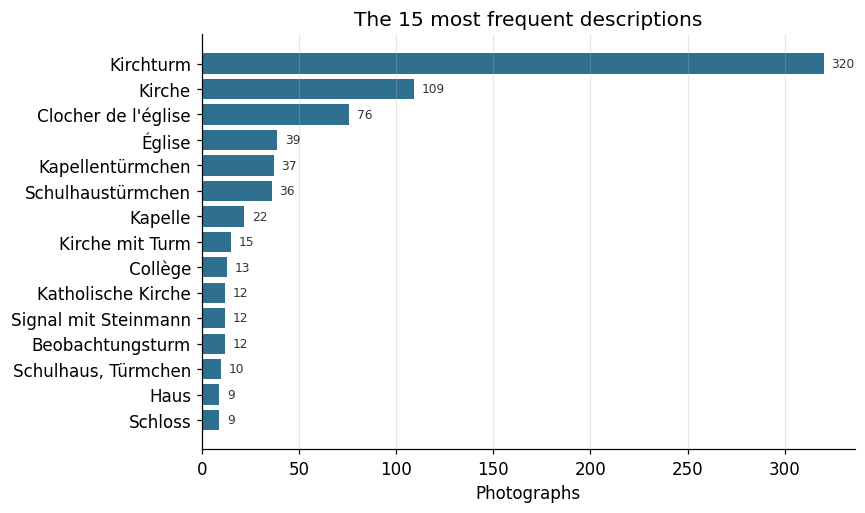

In [9]:
descriptions = photos["Beschreibung"]
description_counts = descriptions.value_counts()
word_counts = descriptions.str.split().str.len()

top = description_counts.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index, top.values, color="#2f6f8f")
for position, value in enumerate(top.values):
    ax.text(value + 4, position, str(value), va="center", fontsize=8, color="#333")
ax.set_xlabel("Photographs")
ax.set_title("The 15 most frequent descriptions")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

once = int((description_counts == 1).sum())
print(
    f"{description_counts.size} distinct descriptions for {len(descriptions)} photographs. "
    f"{once} of them are used once."
)
print(
    f"The 10 most frequent cover {description_counts.head(10).sum() / len(descriptions):.0%} of the photographs, "
    f"the 50 most frequent {description_counts.head(50).sum() / len(descriptions):.0%}."
)
print(
    f"{(word_counts == 1).mean():.0%} of the descriptions are a single word; the median is {int(word_counts.median())} words. "
    f"{int((word_counts >= 10).sum())} run to ten words or more."
)
print("The longest descriptions:")
longest = descriptions.str.len().sort_values(ascending=False).index[:5]
with pd.option_context("display.max_colwidth", None):
    display(photos.loc[longest, ["Inv", "Name2", "Beschreibung"]])

### Language

The descriptions are written in German, French and Italian, and no column records which. The cell below guesses from marker words: nouns such as `Kirchturm`, `clocher` and `campanile`, plus articles and prepositions. A description with no marker word, or with as many markers from two languages, is left undecided. The counts are an estimate.

In [10]:
FRENCH_WORDS = set(
    "église eglise clocher clocheton collège château temple barrage maison école chapelle vue tour tourelle "
    "ferme le les et du de catholique romaine protestante ancienne nouveau pylône salle".split()
)
ITALIAN_WORDS = set(
    "chiesa campanile cippo frana casa convento birraria macello incisione del della dei di nuova strada".split()
)
GERMAN_WORDS = set("und mit der die das von vom im am auf aus für bei zum zur nach neben dem den".split())
GERMAN_STEMS = (
    "kirch", "turm", "türm", "kapell", "schul", "haus", "schloss", "pfeiler", "gipfel", "steinmann", "signal",
    "beobacht", "ingenieur", "seitig", "gerüst", "hütte", "kamin", "gebäude", "aufnahme", "ansicht", "kreuz",
    "reproduktion", "foto", "portrait", "ruine", "messung", "ordnung",
)


def guess_language(text):
    """Language of a description, judged from marker words. Ties and descriptions without a marker stay open."""
    lowered = text.lower()
    tokens = re.findall(r"[a-zà-ÿ]+", lowered)
    scores = {
        "German": sum(token in GERMAN_WORDS or any(stem in token for stem in GERMAN_STEMS) for token in tokens),
        "French": sum(token in FRENCH_WORDS for token in tokens) + len(re.findall(r"\b[ld]'", lowered)),
        "Italian": sum(token in ITALIAN_WORDS for token in tokens),
    }
    best = max(scores.values())
    if best == 0:
        return "no marker word"
    leaders = [language for language, score in scores.items() if score == best]
    return leaders[0] if len(leaders) == 1 else "mixed markers"


photos["description_language"] = descriptions.map(guess_language)

language_order = ["German", "French", "Italian", "mixed markers", "no marker word"]
by_language = photos.groupby("description_language")["Beschreibung"]
language_table = pd.DataFrame({
    "photos": by_language.size(),
    "distinct descriptions": by_language.nunique(),
    "most frequent": by_language.agg(lambda values: " · ".join(values.value_counts().head(4).index)),
}).reindex(language_order)
language_table.insert(1, "share", (language_table["photos"] / len(photos) * 100).map(lambda value: f"{value:.1f}%"))
language_table

,photos,share,distinct descriptions,most frequent
description_language,,,,
German,1341,75.7%,563,Kirchturm · Kirche · Kapellentürmchen · Schulhaustürmchen
French,285,16.1%,109,Clocher de l'église · Église · Collège · Eglise
Italian,45,2.5%,33,"Chiesa, campanile · Campanile · Convento · Birraria"
mixed markers,15,0.8%,14,"Maison ""La Comète"", Haustürmchen · Église paroissiale, Turm · Église, Kirchturm · Convento delle..."
no marker word,85,4.8%,76,Bivouac · Rabattement · Bezirksspital · Scheune


### What the descriptions name

The same subject is written `Kirchturm`, `Clocher de l'église` or `Chiesa, campanile`, so counting raw values undercounts it. The cell below tags each description with themes by keyword, across the three languages. A description can carry more than one theme (`Kapelle und Schulhaus`). `Other building` only takes buildings that are not already a church, a school or a castle.

This is keyword matching, so it is approximate. The descriptions that no keyword reaches are listed under the chart.

The result is kept in two columns next to `Beschreibung`. `Beschreibung-consolidated` holds the themes in English, separated by `; ` when there is more than one, or `uncategorised` when no keyword matched. `Beschreibung-consolidated-keywords` holds the words of the original description that triggered those themes, untranslated and as written.

1696 photographs match at least one theme, 131 match two or three, 75 match none.
785 descriptions (44%) name a tower, turret or belfry. Among churches and chapels it is 68%.
Descriptions no keyword reaches:


,photos
Beschreibung,
Kreuz,6
Reproduktion,3
Beobachtung,2
Rabattement,2
Pierre du Niton,2
Vom Piz Pisoc aus fotografiert,2
Ancienne machine hydraulique - le bâtiment a été démoli A. Projet; B Exécution,2
Ausstellung 125 Jahre L+T,2
Fotoreportage für Sandozkalender,2


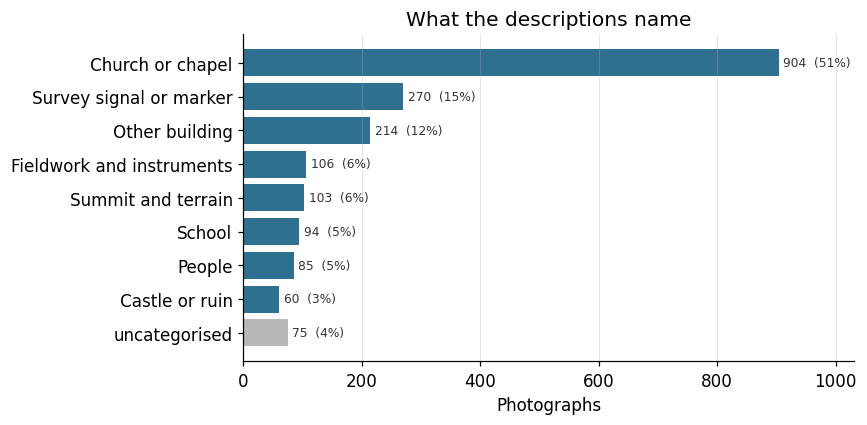

In [11]:
THEMES = {
    "Church or chapel": [
        "kirch", "kichturm", "église", "eglise", "chiesa", "kapell", "chapelle", "temple", "münster",
        "collégiale", "collègiale", "kloster", "convento", "monastero", "synagoge", "campanile", "clocher",
    ],
    "School": ["schulhaus", "schule", "collège", "école", "ecole"],
    "Castle or ruin": ["schloss", "château", "chateau", "ruine", "torturm", "thorturm"],
    "Other building": [
        "haus", "häuschen", "villa", "hotel", "hôtel", r"pension\b", "fabrik", "kamin", "gebäude", "maison",
        "ferme", "casa", "scheune", "spital", "hôpital", "sägerei", "restaura", "café", "anstalt", "barrage",
        "salle", "halle", "macello", "birraria", "chalet", "stall", "hütte", "refuge", "bahnhof", "wirtschaft",
        "kaserne", "sanatorium", "türmchen", "tourelle", "clocheton", "aussichtsturm", r"\btour\b", "pylône",
        "observatoire", "pavillon",
    ],
    "Survey signal or marker": [
        "signal", "pyramide", "pfeiler", "steinmann", "beobachtungsturm", "beobachungsturm", "gerüst", "cippo",
        "incisione", "grenzstein", "borne", "bolzen", "fixpunkt", "versicherung", "zielpunkt", "zielknopf",
        "heliotrop", "blitzableiter", "paratonnerre", "stationspunkt", "fahnenstange",
    ],
    "Fieldwork and instruments": [
        "nivellement", "theodolit", "basismessung", "basisanfang", "triangulation", "instrument", "stativ",
        "messtisch", "transport", "biwak", "bivouac", "zeltlager", "aufstieg", "abstieg", "abmarsch",
        "komparator", "miren", "apparat", "sondierung", "photogrammetrie", "ballon", r"\brast\b", "schlitten",
        "kletterei", "messgruppe", "entfernungsmesser", "offsetpresse", "gravurring", "karussell",
    ],
    "Summit and terrain": [
        "gipfel", "panorama", "blick", "gletscher", "glacier", "firn", "frana", "rutsch", "bergsturz", "riss",
        "arbino", "felszahn", "landschaft", "sasso marcio", "verwerfung",
    ],
    "People": [
        "ingenieur", "portrait", "personenfoto", "gruppenbild", r"topograph\b", r"kartograph\b", "gehilfe",
        "beamter", "besuch", "oberst", "professor", "kupferstecher", "vorsteher", "personal", "mannschaft",
        r"\bgeneral\b",
    ],
}
NO_THEME = "uncategorised"

lowered = descriptions.str.lower()
themes = pd.DataFrame({
    name: lowered.str.contains("|".join(stems), regex=True) for name, stems in THEMES.items()
})
# "Haus" and "Türmchen" sit inside "Schulhaus" and "Kirche mit Türmchen", so the catch-all only
# takes buildings that are not already a church, a school or a castle.
themes["Other building"] &= ~themes[["Church or chapel", "School", "Castle or ruin"]].any(axis=1)
themes[NO_THEME] = ~themes.any(axis=1)

# Largest theme at the top, the unmatched remainder at the bottom.
theme_totals = pd.concat([themes[[NO_THEME]].sum(), themes.drop(columns=NO_THEME).sum().sort_values()])
colors = ["#b8b8b8" if name == NO_THEME else "#2f6f8f" for name in theme_totals.index]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(theme_totals.index, theme_totals.values, color=colors)
for position, value in enumerate(theme_totals.values):
    ax.text(value + 8, position, f"{value}  ({value / len(photos):.0%})", va="center", fontsize=8, color="#333")
ax.set_xlim(0, theme_totals.max() * 1.14)
ax.set_xlabel("Photographs")
ax.set_title("What the descriptions name")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

theme_count = themes.drop(columns=NO_THEME).sum(axis=1)
names_tower = lowered.str.contains(r"turm|türm|clocher|clocheton|campanile|tourelle|\btour\b", regex=True)
print(
    f"{int((theme_count >= 1).sum())} photographs match at least one theme, "
    f"{int((theme_count >= 2).sum())} match two or three, {int(themes[NO_THEME].sum())} match none."
)
print(
    f"{int(names_tower.sum())} descriptions ({names_tower.mean():.0%}) name a tower, turret or belfry. "
    f"Among churches and chapels it is {names_tower[themes['Church or chapel']].mean():.0%}."
)
print("Descriptions no keyword reaches:")
display(descriptions[themes[NO_THEME]].value_counts().head(15).rename("photos").to_frame())

In [12]:
CONSOLIDATED = "Beschreibung-consolidated"
CONSOLIDATED_KEYWORDS = "Beschreibung-consolidated-keywords"

theme_patterns = {
    name: re.compile("|".join(stems), flags=re.IGNORECASE) for name, stems in THEMES.items()
}


def consolidate(text, tagged):
    """English theme labels for one description, and the words in it that triggered them.

    A keyword is often part of a longer word ("kirch" in "Kirchturm"), so each match is
    widened to the whole word and returned as written, in the order it appears.
    """
    assigned = [name for name in THEMES if tagged[name]]
    found = []
    for name in assigned:
        for match in theme_patterns[name].finditer(text):
            start, end = match.span()
            while start > 0 and text[start - 1].isalpha():
                start -= 1
            while end < len(text) and text[end].isalpha():
                end += 1
            found.append((start, text[start:end]))
    words = list(dict.fromkeys(word for _, word in sorted(found)))
    return "; ".join(assigned) or NO_THEME, "; ".join(words) if words else pd.NA


consolidated = [
    consolidate(text, tagged) for text, tagged in zip(descriptions, themes.to_dict("records"))
]
photos[CONSOLIDATED] = [labels for labels, _ in consolidated]
photos[CONSOLIDATED_KEYWORDS] = [words for _, words in consolidated]

# Every categorised description must have at least one keyword, and no uncategorised one may.
assert ((photos[CONSOLIDATED] == NO_THEME) == photos[CONSOLIDATED_KEYWORDS].isna()).all()

# Put the two columns directly after Beschreibung.
other_columns = [column for column in photos.columns if column not in (CONSOLIDATED, CONSOLIDATED_KEYWORDS)]
position = other_columns.index("Beschreibung") + 1
photos = photos[other_columns[:position] + [CONSOLIDATED, CONSOLIDATED_KEYWORDS] + other_columns[position:]]

print(
    f"{photos[CONSOLIDATED].nunique()} distinct values in {CONSOLIDATED}, "
    f"{int((photos[CONSOLIDATED] == NO_THEME).sum())} photographs {NO_THEME}."
)
print("Each value, with its most frequent description and the keywords found in it:")
summary = (
    photos.groupby(CONSOLIDATED)
    .agg(
        photos=("Inv", "size"),
        example=("Beschreibung", lambda values: values.value_counts().index[0]),
    )
    .sort_values("photos", ascending=False)
)
summary["keywords in the example"] = [
    photos.loc[photos["Beschreibung"] == example, CONSOLIDATED_KEYWORDS].iloc[0] for example in summary["example"]
]
display(summary)

keyword_counts = photos[CONSOLIDATED_KEYWORDS].dropna().str.split("; ").explode().value_counts()
print(f"{keyword_counts.size} distinct keywords. The most frequent:")
display(keyword_counts.head(20).rename("photos").to_frame())

29 distinct values in Beschreibung-consolidated, 75 photographs uncategorised.
Each value, with its most frequent description and the keywords found in it:


,photos,example,keywords in the example
Beschreibung-consolidated,,,
Church or chapel,894,Kirchturm,Kirchturm
Other building,189,Haus,Haus
Survey signal or marker,176,Beobachtungsturm,Beobachtungsturm
School,89,Schulhaustürmchen,Schulhaustürmchen
uncategorised,75,Kreuz,NaN
Fieldwork and instruments,60,Steintransporte für die Triangulation IV. Ordnung,Steintransporte; Triangulation
Summit and terrain,54,Gipfelansicht,Gipfelansicht
People,53,Personenfotos in Wabern,Personenfotos
Castle or ruin,50,Schloss,Schloss


324 distinct keywords. The most frequent:


,photos
Beschreibung-consolidated-keywords,
Kirchturm,394
Kirche,201
Signal,98
église,90
Clocher,88
Église,64
Kapellentürmchen,45
Kapelle,44
Steinmann,43


Photographs behind those shares:


period,before 1900,1900–1909,1910–1919,1920–1929,1930–2000,no single year
Church or chapel,75,41,346,288,8,146
Survey signal or marker,3,11,192,42,11,11
Other building,31,5,74,85,0,19
Fieldwork and instruments,3,21,68,9,5,0
Summit and terrain,5,4,52,40,2,0
School,6,0,47,23,0,18
People,7,6,31,10,18,13
Castle or ruin,16,1,20,17,0,6
uncategorised,8,1,25,17,10,14


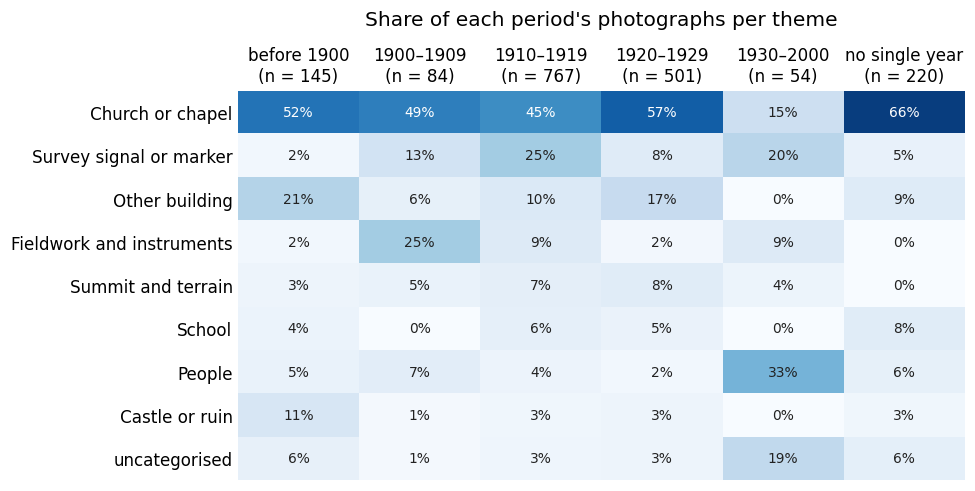

In [13]:
periods = pd.cut(
    photos["year"].astype("float"),
    bins=[1800, 1899, 1909, 1919, 1929, 2000],
    labels=["before 1900", "1900–1909", "1910–1919", "1920–1929", "1930–2000"],
).cat.add_categories("no single year").fillna("no single year").rename("period")
period_sizes = periods.value_counts().sort_index()
theme_rows = list(theme_totals.index[::-1])
by_period = themes.groupby(periods, observed=False).sum().T.loc[theme_rows]
share = by_period / period_sizes * 100

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.imshow(share.values, cmap="Blues", vmin=0, vmax=70, aspect="auto")
ax.set_xticks(range(share.shape[1]), [f"{label}\n(n = {period_sizes[label]})" for label in share.columns])
ax.set_yticks(range(share.shape[0]), share.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
for row in range(share.shape[0]):
    for column in range(share.shape[1]):
        value = share.values[row, column]
        ax.text(
            column, row, f"{value:.0f}%", ha="center", va="center", fontsize=9,
            color="white" if value > 40 else "#222",
        )
ax.set_title("Share of each period's photographs per theme", pad=14)
fig.tight_layout()

print("Photographs behind those shares:")
display(by_period)

### Notes and spelling

Two things in the field get in the way of grouping by description. Some descriptions end with an editorial note in square brackets: the stereo partner of the image, the state of the negative, or a clarified place name. And the same description is sometimes spelled more than one way.

In [14]:
notes = (
    descriptions.str.extractall(r"\[(?P<note>[^\]]*)\]")
    .reset_index(level="match", drop=True)
    .join(photos[["Inv", "nummer", "Name2"]])
)


def note_kind(note):
    if note.startswith("Stereobild mit"):
        return "Stereo partner"
    if re.search(r"degradiert|Glasbruch|Retuschiert|Fehlbelichtung", note):
        return "Condition of the negative"
    if note.startswith("Instrumentenbeschreibung"):
        return "Instrument record"
    return "Place name or clarification"


notes["kind"] = notes["note"].map(note_kind)
print(f"{notes.index.nunique()} descriptions carry a note in square brackets")
display(
    notes.groupby("kind").agg(
        photos=("note", "size"),
        example=("note", lambda values: values.iloc[0][:70]),
    ).sort_values("photos", ascending=False)
)

# A stereo note names its partner as 000-392-180, which is the inventory number 392180.
stereo = notes[notes["kind"] == "Stereo partner"].copy()
stereo["partner"] = stereo["note"].str.extract(r"(\d{3}-\d{3}-\d{3})")[0].str.replace("-", "").astype(int)
points_back = dict(zip(stereo["Inv"], stereo["partner"]))
stereo["link"] = [
    "names its own number" if partner == inv
    else "reciprocal pair" if points_back.get(partner) == inv
    else "one-way"
    for inv, partner in zip(stereo["Inv"], stereo["partner"])
]
print(
    f"{int(stereo['partner'].isin(photos['Inv']).sum())} of {len(stereo)} stereo partners "
    f"are inventory numbers in this table"
)
display(stereo["link"].value_counts().rename("photos").to_frame())
print("Stereo notes that do not form a reciprocal pair:")
display(stereo.loc[stereo["link"] != "reciprocal pair", ["Inv", "nummer", "Name2", "partner", "link"]])

40 descriptions carry a note in square brackets


,photos,example
kind,,
Stereo partner,29,Stereobild mit 000-392-180
Place name or clarification,6,Goppenstein
Condition of the negative,4,Fotografie stark degradiert
Instrument record,1,Instrumentenbeschreibung: Selber oder gleicher Theodolit in der Instru


29 of 29 stereo partners are inventory numbers in this table


,photos
link,
reciprocal pair,20
names its own number,8
one-way,1


Stereo notes that do not form a reciprocal pair:


,Inv,nummer,Name2,partner,link
1112,392183,1681b,Orsières,392183,names its own number
1113,392184,1681d,Orsières,392184,names its own number
1120,392210,1685c,Termen,392210,names its own number
1121,392211,1685d,Termen,392211,names its own number
1122,392213,1686a,Col du Grand St-Bernard,392213,names its own number
1123,392214,1686b,Col du Grand St-Bernard,392214,names its own number
1124,392230,1687a,"Bern, Kirchenfeld",392230,names its own number
1125,392231,1687b,"Bern, Kirchenfeld",392231,names its own number
1128,392242,1689a,Landestopografie,392207,one-way


In [15]:
import difflib
import itertools
import unicodedata


def squash(text):
    """Lower-case, strip accents, drop everything that is not a letter or digit."""
    text = unicodedata.normalize("NFKD", text.casefold())
    text = "".join(char for char in text if not unicodedata.combining(char))
    return re.sub(r"[^a-z0-9]+", "", text)


# Compare the descriptions without their bracketed notes, so "Kapelle [Glasbruch]" counts as "Kapelle".
core = descriptions.str.replace(r"\s*\[[^\]]*\]", "", regex=True).str.strip()
keys = core.map(squash)
spellings = core.groupby(keys).agg(lambda values: values.value_counts().to_dict())
same_key = spellings[spellings.map(len) > 1]
print(f"{len(same_key)} descriptions are written more than one way (case, accents, spacing, punctuation):")
display(
    pd.DataFrame({
        "spellings": same_key.map(lambda found: " | ".join(f"{text} ({count})" for text, count in found.items())),
        "photos": same_key.map(lambda found: sum(found.values())),
    }).sort_values("photos", ascending=False).reset_index(drop=True)
)

# Near-misses: almost the same string once squashed, with the same digits, so that
# "3-seitig" and "4-seitig" or two different years are not paired.
key_counts = keys.value_counts()
label = core.groupby(keys).agg(lambda values: values.value_counts().index[0])
candidates = [key for key in key_counts.index if len(key) >= 7]
near = []
for first, second in itertools.combinations(candidates, 2):
    if abs(len(first) - len(second)) > 2 or re.findall(r"\d+", first) != re.findall(r"\d+", second):
        continue
    ratio = difflib.SequenceMatcher(None, first, second).ratio()
    if ratio >= 0.93:
        near.append({
            "more frequent": f"{label[first]} ({key_counts[first]})",
            "less frequent": f"{label[second]} ({key_counts[second]})",
            "similarity": round(ratio, 3),
        })
print(f"{len(near)} near-identical pairs. This is a list to review: some are typos, some are real differences.")
display(pd.DataFrame(near).sort_values("similarity", ascending=False).reset_index(drop=True))

11 descriptions are written more than one way (case, accents, spacing, punctuation):


,spellings,photos
0,Église (39) | Eglise (8),47
1,"Schulhaustürmchen (36) | Schulhaus, Türmchen (10)",46
2,Reformierte Kirche (8) | reformierte Kirche (1),9
3,Gipfelansicht (4) | Gipfel-Ansicht (1),5
4,Pyramide und Beobachtungs-Pfeiler (4) | Pyramide und Beobachtungspfeiler (1),5
5,Hauskamin (2) | Haus-Kamin (1),3
6,"Anstalttürmchen (1) | Anstalt, Türmchen (1)",2
7,"Haus, Türmchen (1) | Haustürmchen (1)",2
8,"Hotel ""Des Alpes"" (1) | Hôtel des Alpes (1)",2
9,"Kirchturm der alten Kirche (1) | Kirchturm, der alten Kirche (1)",2


9 near-identical pairs. This is a list to review: some are typos, some are real differences.


,more frequent,less frequent,similarity
0,"Refomierte Kirche, Kirchturm (8)","Reformierte Kirche, Kirchturm (5)",0.980
1,Personenfotos in Wabern (5),Personenfoto in Wabern (3),0.976
2,Anstalttürmchen (2),Anstaltstürmchen (1),0.968
3,"Frana del Motto d'Arbino, Nordhang M. Arbino, Aufnahme West (1)","Frana del Motto d'Arbino, Nordhang M. Arbino, Aufnahme Ost (1)",0.968
4,"Église catholique romaine, vue de ouest (1)","Église catholique romaine, vue de l'est (1)",0.954
5,"Kapelle San Zenone, Turmseite, Triangulation Taverne, Signal N. 5 (1)","Kapelle San Zenone, Rückseite, Triangulation Taverne, Signal N. 5 (1)",0.943
6,Kirchturm (320),Kichturm (2),0.941
7,Kapellentürmchen (37),Kapelltürmchen (6),0.933
8,Torturm (2),Thorturm (1),0.933


## Places

Three place slots can be filled: the place depicted (`Abgebildeter_Ort`), the camera position (`Aufnahmeort`), and a related place (`Verbundener_Ort`). Each slot has a name, LV95 coordinates, a source, and a GND identifier. Several values in one cell are separated by a semicolon; the map keeps the first, and so does the scatter below.

`Ortsfinder_Status` records the review: `verortet` (a place was assigned), `zurückgestellt` (set aside), or `keine Geodaten` (no geodata). A blank status means the row has not been through that review. The review dates sit in October and November 2026.

In [16]:
def first_number(value):
    """First number in a cell. '2593463; ' and '2603726; 2601392' both yield the first one."""
    if pd.isna(value):
        return None
    for part in str(value).split(";"):
        part = part.strip()
        if not part:
            continue
        try:
            return float(part)
        except ValueError:
            return None
    return None


def part_count(value):
    if pd.isna(value):
        return 0
    return len([part for part in str(value).split(";") if part.strip()])


for role, prefix in (
    ("depicted", "Abgebildeter_Ort"),
    ("camera", "Aufnahmeort"),
    ("related", "Verbundener_Ort"),
):
    photos[f"{role}_name"] = photos[f"{prefix}_Name"]
    photos[f"{role}_e"] = photos[f"{prefix}_E_LV95"].map(first_number)
    photos[f"{role}_n"] = photos[f"{prefix}_N_LV95"].map(first_number)
    photos[f"{role}_parts"] = photos[f"{prefix}_Name"].map(part_count)

photos["status"] = photos["Ortsfinder_Status"].fillna("(blank)")
photos["has_coordinates"] = photos["depicted_e"].notna() | photos["camera_e"].notna() | photos["related_e"].notna()

status_order = ["verortet", "zurückgestellt", "keine Geodaten", "(blank)"]
crosstab = pd.crosstab(
    photos["status"],
    photos["has_coordinates"].map({True: "has coordinates", False: "no coordinates"}),
).reindex(status_order)
crosstab["photos"] = crosstab.sum(axis=1)
crosstab

has_coordinates,has coordinates,no coordinates,photos
status,,,
verortet,152,22,174
zurückgestellt,2,45,47
keine Geodaten,0,11,11
(blank),0,1539,1539


In [17]:
role_rows = []
for role, label in (("depicted", "Place depicted"), ("camera", "Camera position"), ("related", "Related place")):
    role_rows.append({
        "role": label,
        "name": int(photos[f"{role}_name"].notna().sum()),
        "coordinates": int(photos[f"{role}_e"].notna().sum()),
        "more than one value": int((photos[f"{role}_parts"] > 1).sum()),
    })
pd.DataFrame(role_rows)

,role,name,coordinates,more than one value
0,Place depicted,160,144,17
1,Camera position,13,12,1
2,Related place,1,1,0


Depicted places outside the rough Swiss LV95 window: 0
Review dates:


,photos
Ortsfinder_Datum,
2026-10-29,11
2026-10-30,92
2026-11-01,2
2026-11-03,3
2026-11-04,93
2026-11-05,16
2026-11-10,15


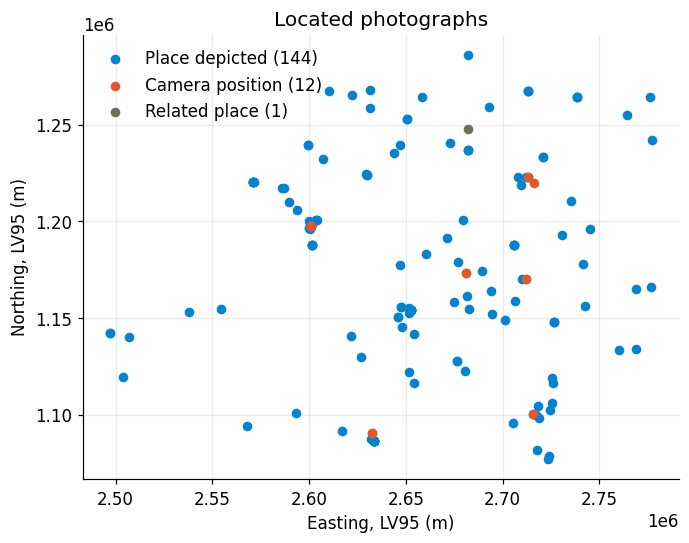

In [18]:
# Same colours as the points on the map: depicted in blue, camera position in orange.
role_style = {
    "depicted": ("#0382d1", "Place depicted"),
    "camera": ("#e4572e", "Camera position"),
    "related": ("#6b705c", "Related place"),
}

fig, ax = plt.subplots(figsize=(6.4, 6.4))
for role, (color, label) in role_style.items():
    points = photos.dropna(subset=[f"{role}_e", f"{role}_n"])
    ax.scatter(
        points[f"{role}_e"], points[f"{role}_n"],
        s=28, color=color, label=f"{label} ({len(points)})", zorder=3,
    )
ax.set_aspect("equal")
ax.set_xlabel("Easting, LV95 (m)")
ax.set_ylabel("Northing, LV95 (m)")
ax.set_title("Located photographs")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()

swiss_e = photos["depicted_e"].between(2_485_000, 2_834_000)
swiss_n = photos["depicted_n"].between(1_075_000, 1_296_000)
outside = photos[photos["depicted_e"].notna() & ~(swiss_e & swiss_n)]
print(f"Depicted places outside the rough Swiss LV95 window: {len(outside)}")
print("Review dates:")
display(photos["Ortsfinder_Datum"].dropna().value_counts().sort_index().rename("photos").to_frame())

In [19]:
named_without_point = photos[photos["depicted_name"].notna() & photos["depicted_e"].isna()]
print(f"Depicted place has a name and no coordinates: {len(named_without_point)}")
print("All of them were matched in GND, which identifies the place and carries no LV95 point.")
display(named_without_point[["Inv", "Name2", "depicted_name", "Abgebildeter_Ort_Quelle", "status"]])

no_place = photos[
    (photos["status"] == "verortet")
    & photos[["depicted_name", "camera_name", "related_name"]].isna().all(axis=1)
]
print(f"Marked verortet, with no place name in any slot: {len(no_place)}")
display(no_place[["Inv", "Name2", "Beschreibung"]])

print("Source of the depicted place")
display(photos["Abgebildeter_Ort_Quelle"].value_counts(dropna=False).rename("photos").to_frame())

several_roles = photos[
    (photos[["depicted_name", "camera_name", "related_name"]].notna().sum(axis=1) >= 2)
]
print(f"Photographs with more than one place role filled: {len(several_roles)}")
display(several_roles[["Inv", "Name2", "depicted_name", "camera_name", "related_name", "status"]])

Depicted place has a name and no coordinates: 16
All of them were matched in GND, which identifies the place and carries no LV95 point.


,Inv,Name2,depicted_name,Abgebildeter_Ort_Quelle,status
27,389717,Simmenthal [Simmental],Simmental,GND,verortet
29,389720,Simmenthal [Simmental],Simmental,GND,verortet
74,389766,Pizzo di Claro,Pizzo di Claro,GND,verortet
75,389767,Pizzo di Claro,Pizzo di Claro,GND,verortet
76,389768,Pizzo di Claro,Pizzo di Claro,GND,verortet
82,389776,Finsteraarhorn,Finsteraarhorn,GND,verortet
93,389793,Finsteraarhorn,Finsteraarhorn,GND,verortet
94,389794,Finsteraarhorn,Finsteraarhorn,GND,verortet
97,389833,Finsteraarhorn,Finsteraarhorn; Schreckhorn; Lauteraarhorn,GND; GND; GND,verortet
98,389839,Finsteraarhorn,Finsteraarhorn,GND,verortet


Marked verortet, with no place name in any slot: 7


,Inv,Name2,Beschreibung
3,389693,Grafenort,Stangensignal 4. Ordnung
1708,398065,Stereoskopisches Sehen,Entfernungsmesser
1709,398501,Hauser Eugen,Ingenieur
1712,399257,Gravurring,Gravurring mit Lupe im Zentrum
1739,431307,Fotoreportage von Fernand Rausser,Fotoreportage für Sandozkalender
1762,448646,Kägi Ernst,Kupferstecher T.D.II
1764,450942,Müller Walter,"Umdrucker T.D.II, Aufnahme 1977 zur Pensionierung"


Source of the depicted place


,photos
Abgebildeter_Ort_Quelle,
NaN,1611
swisstopo,126
GND,15
swisstopo; GND,9
swisstopo; swisstopo,5
manuell,2
swisstopo; swisstopo; swisstopo,1
GND; GND; GND,1
swisstopo; swisstopo; swisstopo; swisstopo,1


Photographs with more than one place role filled: 5


,Inv,Name2,depicted_name,camera_name,related_name,status
100,389845,Monte Rosa,Monte Rosa,Gornergletscher,NaN,verortet
108,389859,Monte Rosa,Monte Rosa,Gornergletscher,NaN,verortet
152,389941,San Zenone [Lamone],San Zenone,Lamone,NaN,verortet
601,390793,Piotta,Piotta,Piotta,NaN,verortet
1730,422211,Aletschgletscher-Vermessung 1957,Grosser Aletschgletscher,NaN,Zürich,verortet


In [20]:
multi = photos[photos["depicted_parts"] > 1]
print(f"Depicted place has several names or coordinate pairs: {len(multi)}")
display(multi[["Inv", "Name2", "Abgebildeter_Ort_Name", "Abgebildeter_Ort_E_LV95", "Abgebildeter_Ort_N_LV95"]])

uncertain = photos[photos["Name2"].str.contains(r"\[", na=False)]
print(f"Titles that hedge the identification with square brackets: {len(uncertain)}")
display(uncertain[["Inv", "Name2", "depicted_name", "status"]].head(15))

Depicted place has several names or coordinate pairs: 17


,Inv,Name2,Abgebildeter_Ort_Name,Abgebildeter_Ort_E_LV95,Abgebildeter_Ort_N_LV95
49,389740,Ostermundigen,Ostermundigen; Wylerfeld,2603726; 2601392,1200726; 1201778
81,389775,Six Madun,Six Madun; Badus Six Madun,2693824;,1164205;
85,389779,"Fieschertal, Finsteraarhornhütte SAC",Finsteraarhornhütte SAC; Fieschertal,2651858; 2654159,1152519; 1141567
86,389780,Finsteraarhorn,Finsteraarhorn; Finsteraarhorn,2652735;,1154237;
87,389782,Finsteraarhorn,Finsteraarhorn; Finsteraarhorn,2652735;,1154237;
88,389783,Konkordiaplatz,Konkordiaplatz; Dreieckhorn; Aletschhorn,2645822; 2644658; 2642627,1150453; 1147569; 1146132
89,389784,Finsteraarhorn,Finsteraarhorn; Finsteraarhorn,2652735;,1154237;
90,389790,Finsteraarhorn,Finsteraarhorn; Finsteraarhorn,2652735;,1154237;
91,389791,Fieschertal,Fieschertal; Binntal,2654159; 2661087,1141567; 1135765
92,389792,Finsteraarhorn,Finsteraarhorn; Hugisattel,2652735; 2652520,1154237; 1154518


Titles that hedge the identification with square brackets: 59


,Inv,Name2,depicted_name,status
1,389691,[Wahrscheinlich Rämel],Rämel,verortet
2,389692,[Wahrscheinlich Rämel],Rämel,verortet
27,389717,Simmenthal [Simmental],Simmental,verortet
29,389720,Simmenthal [Simmental],Simmental,verortet
53,389744,Sonnenberg bei Möhlin [Sunnenberg],Möhlin,zurückgestellt
54,389745,Poncione della Freccione [Puntone dei Fraciòn],Poncione,zurückgestellt
61,389752,Scheerhorn [Schärhorn],Schärhorn,verortet
62,389753,Scheerhorn [Schärhorn],Schärhorn,verortet
63,389754,Scheerhorn [Schärhorn],Schärhorn,verortet
64,389755,Scheerhorn [Schärhorn],Schärhorn,verortet


## Reading so far

The catalogue is complete as an inventory: 1,771 photographs once the 7 duplicated ids are collapsed, each with a title and a description. The descriptions repeat because the collection is full of series. Church towers and churches dominate them (`Kirchturm` 320, `Kirche` 109, `Clocher de l'église` 76), alongside chapel towers, schoolhouse towers and triangulation signals.

The descriptions are short. There are 795 distinct values, 45% of the photographs are described in a single word, and the ten most frequent values cover 38% of the photographs. By the marker-word estimate, about three quarters are in German, one in six in French and a few dozen in Italian. Read by keyword across the three languages, 904 photographs (51%) show a church or chapel, and 44% of all descriptions name a tower, turret or belfry. Survey signals and markers follow with 270. Churches are about half of every period up to 1929. Survey signals peak in the 1910s at 25%, and in the 54 photographs from 1930 on, people are the largest theme. 29 descriptions name a stereo partner by inventory number: 20 form reciprocal pairs, 8 name their own number, and 1 points to a photograph of a different subject.

1,551 photographs resolve to a single year, from 1852 to 2000. 217 have no year. Two span a range (`1935–1936`, `1910–1950`) and one is only an upper bound (`before 1906`). Of the dated photographs, 82% fall in 1910–1929, and 1919 alone accounts for 338, of which 330 are recorded as a whole year. 135 of those years come from reading `Apr-21` and `6/16/01` as dates, which a four-digit search on the CSV text would miss. The map already has them, because `convertir_donnees.py` reads the Excel file, where those cells are real dates.

Geolocation covers a reviewed sample. 232 photographs have an Ortsfinder status (174 `verortet`, 47 `zurückgestellt`, 11 `keine Geodaten`) and 1,539 have none. 154 have coordinates, all inside Switzerland. The depicted place is the one usually filled (160 names, 144 points). A camera position is filled 13 times, a related place once. The 16 depicted names without a point all come from GND: the place is identified, and the LV95 coordinate is absent. Seven further rows are marked `verortet` and have no place name at all: portraits, objects, and Grafenort, whose place is only in the title. 17 depicted places list more than one candidate, and 59 titles hedge the identification in square brackets.

The next cuts that follow from this are the 217 photographs with no year, the GND matches that still need a coordinate, and the bracketed titles, before locating the 1,539 rows that have not been reviewed.